# 3.11 Forests in practice

🖥️ [**Lecture slides, Session 17 (Fri Nov 6)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec17_trees_forests_honestly.html)

Forests are the default model for feature tables in the geosciences: snow instability in the Swiss Alps (Mayer et al., 2022), global soil maps (Poggio et al., 2021), seismic source types in the Pacific Northwest (Kharita et al., 2026). This notebook uses two data sets. For classes, the 4,000 Pacific Northwest seismic events of notebooks 3.3 and 3.5. For numbers, ten years of daily soil and air measurements at a U.S. Climate Reference Network station in eastern Washington.

**Learning outcomes.** By the end of this notebook you can:

1. compute recall and false-positive rate at a threshold, and say how a ROC curve collects them;
2. show that a full decision tree memorizes its training events, and that many trees do better on new ones;
3. read a forest's out-of-bag score as an estimate of its test score;
4. show that one threshold means different things for two models with the same ROC curve;
5. compare a regression forest with climatology and with yesterday's value;
6. explain why a copy of a feature changes its importance and not the error;
7. say why a forest cannot predict beyond the range of its training values.

**Time:** about 35 minutes in pairs. If you run short, skip Parts 2 and 6.

## How this notebook works

Each **Your turn** cell asks for a few lines of code. Read the hint, write your answer where the cell says, and run it. The cell below it holds a worked solution, hidden until you click ⋯. That hidden cell also checks your answer: it prints `correct`, or a hint, and if your answer is missing or different it uses the reference result so that the rest of the notebook still runs. Your own answer, if different, is kept under the same name followed by `_yours`.

In [1]:
# Data handling
import hashlib
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import pooch

# Plotting
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

# Models and scores (scikit-learn)
from sklearn.datasets import make_classification   # synthetic stand-in if Zenodo cannot be reached
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import f1_score, mean_absolute_error, r2_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

The values below are used in several places, so they are defined once. The figure colors stay distinct for color-blind readers (the Okabe-Ito palette).

In [2]:
SEED = 42
SPLIT_SEED = 2026                  # the canonical split of notebook 3.5
THRESHOLDS = [0.8, 0.5, 0.2]       # decision thresholds on the probability of explosion
N_TREES = 300
RAIN_DAY_MM = 5.0                  # a day with at least this much rain counts as rainy
COOL_LIMIT_C = 28.0                # Part 7: train only on days with a maximum air temperature below this
BLUE, ORANGE, GREEN, RED, INK, MUTED = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#26241f", "#6e675c"
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Helper: compare an answer with a reference. If the answer is missing or different, print a hint and use the
# reference so the cells below still run; a different answer is kept as <name>_yours.
def check(name, ns, reference, hint, measure=None, tol=1e-3):
    measure = measure or (lambda value: np.asarray(value, dtype=float))
    yours = ns.get(name)
    if yours is None or (hasattr(yours, "__len__") and len(yours) == 0):
        print(f"{name}: not answered yet. Hint: {hint}\n  Using the reference result below.")
    else:
        try:
            ok = np.allclose(measure(yours), measure(reference), atol=tol)
        except Exception:
            ok = False
        if ok:
            print(f"{name}: correct")
            return
        print(f"{name}: not the expected result. Hint: {hint}\n  Your answer is kept as {name}_yours; "
              "the reference is used below.")
        ns[f"{name}_yours"] = yours
    ns[name] = reference

## The seismic events

📍 In-situ sensor · 🪨 Solid Earth · 📈 Seismology

Each data sample is one seismic event recorded by the Pacific Northwest Seismic Network, described by 61 features computed from its waveform (Zenodo record [14025693](https://zenodo.org/records/14025693)). An analyst labeled each one as an earthquake, an explosion, a surface event or noise, with 1,000 of each. Keep in mind that this table has been balanced by selection, while the real stream has not. Kharita et al. (2026) show the map of these events and the larger study behind this table.

The next cell downloads the tables once and makes the canonical split of notebook 3.5: 3,000 events to train and 1,000 to test. It also makes the two-class version of Wednesday's lecture, explosion against earthquake.

In [4]:
SEISMIC_FILES = {
    "1000_earthquakes_physical_features.csv": "md5:28129c8dd1b3e14f655d489577b841b5",
    "1000_explosion_physical_features.csv": "md5:af1342d32e163e961e043364136359b0",
    "1000_noise_physical_features.csv": "md5:16cdb992fed6cf6273d5624f5df905da",
    "1000_surface_physical_features.csv": "md5:9a2c2643030cf058704d68e130654e9d",
}
try:
    tables = [pd.read_csv(pooch.retrieve(url=f"https://zenodo.org/api/records/14025693/files/{name}/content",
                                         known_hash=checksum, fname=name, path=pooch.os_cache("mlgeo")), index_col=0)
              for name, checksum in SEISMIC_FILES.items()]
    seismic = pd.concat(tables, ignore_index=True).dropna(axis=1)
    X = seismic.drop(columns=["source", "serial_no"])
    y = seismic["source"]
except Exception as error:
    print(f"Zenodo could not be reached ({error}). Using SYNTHETIC events: the scores below will differ from the text.")
    values, codes = make_classification(n_samples=4000, n_features=61, n_informative=20, n_classes=4, random_state=SEED)
    X = pd.DataFrame(values, columns=[f"feature_{i}" for i in range(61)])
    y = pd.Series(np.array(["earthquake", "explosion", "noise", "surface event"])[codes])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SPLIT_SEED, stratify=y)

two = y.isin(["earthquake", "explosion"])
Xb_train, Xb_test, yb_train, yb_test = train_test_split(X[two], (y[two] == "explosion").astype(int), test_size=0.25,
                                                        random_state=SPLIT_SEED, stratify=y[two])
print(f"Four classes: {len(X_train)} training events, {len(X_test)} test events, {X.shape[1]} features")
print(f"Two classes: {len(Xb_train)} training events, {len(Xb_test)} test events")

Four classes: 3000 training events, 1000 test events, 61 features
Two classes: 1500 training events, 500 test events


## Part 1. A ROC curve from ten events

The table below holds ten real test events with the probability of explosion given by Wednesday's logistic regression. They were chosen to include every kind of error, so the curve they give is worse than the model's full curve.

**On paper first, if you have not done it yet.** Start at (0, 0) and go down the list: for an explosion move up 0.2; for an earthquake move right 0.2. Circle where you stand at thresholds 0.8, 0.5 and 0.2.

In [5]:
ten = pd.DataFrame({
    "probability": [0.97, 0.90, 0.72, 0.62, 0.40, 0.37, 0.15, 0.12, 0.06, 0.02],
    "analyst": ["explosion", "explosion", "earthquake", "explosion", "earthquake",
                "explosion", "earthquake", "explosion", "earthquake", "earthquake"],
})
ten_p = ten["probability"].to_numpy()
ten_y = (ten["analyst"] == "explosion").astype(int).to_numpy()
ten

,probability,analyst
0,0.97,explosion
1,0.90,explosion
2,0.72,earthquake
3,0.62,explosion
4,0.40,earthquake
5,0.37,explosion
6,0.15,earthquake
7,0.12,explosion
8,0.06,earthquake
9,0.02,earthquake


### Your turn (1): recall and false-positive rate at a threshold

Write a function `rates(labels, probabilities, threshold)` that returns two numbers: the **recall** (of the true explosions, the share with a probability at or above the threshold) and the **false-positive rate** (of the true earthquakes, the share at or above the threshold). `labels` holds 1 for explosion and 0 for earthquake; both inputs are arrays.

*Hint:* `flagged = probabilities >= threshold`, then `flagged[labels == 1].mean()` and `flagged[labels == 0].mean()`.

In [6]:
rates = None   # replace this line with your function: def rates(labels, probabilities, threshold): ...

*Worked solution below (click ⋯ to open it).*

In [7]:
def rates_sol(labels, probabilities, threshold):
    flagged = probabilities >= threshold
    return flagged[labels == 1].mean(), flagged[labels == 0].mean()


def rates_on_ten(function):
    return [function(ten_y, ten_p, t) for t in THRESHOLDS]


check("rates", globals(), rates_sol, "flagged = probabilities >= threshold; then the mean of flagged for each class.", measure=rates_on_ten)

rates: not answered yet. Hint: flagged = probabilities >= threshold; then the mean of flagged for each class.
  Using the reference result below.


Compare with your drawing: each threshold gives one confusion matrix, and so one point. Then see where the full curve of the same model lies, on all 500 test events.

In [8]:
binary_logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xb_train, yb_train)
p_logistic = binary_logistic.predict_proba(Xb_test)[:, 1]
labels_test = yb_test.to_numpy()

for t in THRESHOLDS:
    recall, false_positive_rate = rates(ten_y, ten_p, t)
    print(f"threshold {t}: recall {recall:.1f}, false-positive rate {false_positive_rate:.1f}")
print(f"AUC: ten events {roc_auc_score(ten_y, ten_p):.2f}, all 500 test events {roc_auc_score(labels_test, p_logistic):.3f}")

threshold 0.8: recall 0.4, false-positive rate 0.0
threshold 0.5: recall 0.6, false-positive rate 0.2
threshold 0.2: recall 0.8, false-positive rate 0.4
AUC: ten events 0.76, all 500 test events 0.963


In [9]:
# Helper: the ten-event curve on top of the curve of all test events.
def plot_ten_events():
    fig, ax = plt.subplots(figsize=(5.2, 4.8))
    fpr, tpr, _ = roc_curve(labels_test, p_logistic)
    ax.plot(fpr, tpr, color=BLUE, lw=2, label="all 500 test events")
    fpr, tpr, _ = roc_curve(ten_y, ten_p)
    ax.plot(fpr, tpr, color=RED, lw=2, marker="o", ms=3, label="ten events")
    for t in THRESHOLDS:
        recall, false_positive_rate = rates(ten_y, ten_p, t)
        ax.plot(false_positive_rate, recall, "o", ms=10, mfc="white", mec=RED, mew=2)
        ax.annotate(f"{t}", (false_positive_rate, recall), xytext=(8, -14), textcoords="offset points", color=RED)
    ax.plot([0, 1], [0, 1], color=MUTED, ls=":")
    ax.set(xlabel="False-positive rate", ylabel="Recall", title="Pacific Northwest events, Zenodo 14025693")
    ax.legend(frameon=False, loc="lower right")
    plt.show()

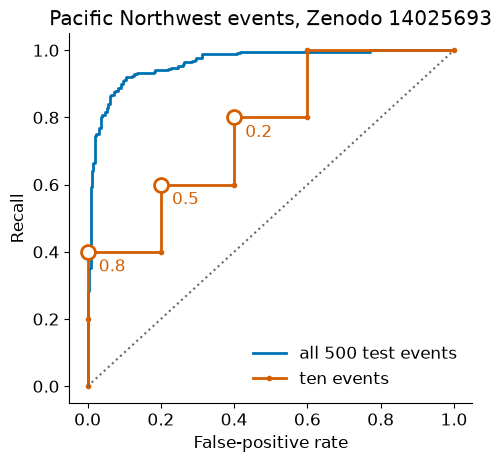

In [10]:
plot_ten_events()

## Part 2. One tree (skip if short of time)

A tree asks a sequence of questions, each a threshold on one feature. Print a small one and read it aloud. Note the word: a **split threshold** acts on a feature, while the decision threshold of Part 1 acts on a probability.

In [11]:
small_tree = DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(X_train, y_train)
print(export_text(small_tree, feature_names=list(X.columns)))

|--- Kurto_3_10 <= 1.49
|   |--- Kurto_1_3 <= 2.54
|   |   |--- class: noise
|   |--- Kurto_1_3 >  2.54
|   |   |--- class: explosion
|--- Kurto_3_10 >  1.49
|   |--- DistMaxMedianFreqDTF <= 0.01
|   |   |--- class: earthquake
|   |--- DistMaxMedianFreqDTF >  0.01
|   |   |--- class: surface event



### Your turn (2): how deep?

Fill `depth_scores`, a list with one row `[depth, train_f1, test_f1]` for each depth in `DEPTHS`. Fit a `DecisionTreeClassifier(max_depth=depth, random_state=SEED)` on `X_train, y_train`, and score it with the macro-F1 of Wednesday, once on the training events and once on the test events. `None` means no limit.

*Hint:* `f1_score(y_train, tree.predict(X_train), average="macro")`.

In [12]:
DEPTHS = [1, 2, 3, 5, 8, 12, None]

In [13]:
depth_scores = []
# --- your code: a loop over DEPTHS that appends [depth, train_f1, test_f1]

# --- end

*Worked solution below (click ⋯ to open it).*

In [14]:
depth_scores_sol = []
for depth in DEPTHS:
    tree_sol = DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(X_train, y_train)
    depth_scores_sol.append([depth, f1_score(y_train, tree_sol.predict(X_train), average="macro"),
                             f1_score(y_test, tree_sol.predict(X_test), average="macro")])
check("depth_scores", globals(), depth_scores_sol, "fit one tree per depth; score train and test with average='macro'.",
      measure=lambda rows: [row[1:] for row in rows])

depth_scores: not answered yet. Hint: fit one tree per depth; score train and test with average='macro'.
  Using the reference result below.


In [15]:
pd.DataFrame([["full" if row[0] is None else row[0], *row[1:]] for row in depth_scores], columns=["depth", "macro-F1, training events", "macro-F1, test events"]).round(3)

,depth,"macro-F1, training events","macro-F1, test events"
0,1,0.345,0.340
1,2,0.572,0.568
2,3,0.764,0.756
3,5,0.821,0.792
4,8,0.916,0.825
5,12,0.990,0.808
6,full,1.000,0.800


Where do the two columns start to separate? The last row is a tree that has memorized its training events.

## Part 3. Many trees

A forest trains each tree on a bootstrap of the events (drawn with replacement, about 37% left out each time) and offers each split a random subset of the features. Each event can then be scored by the trees that never saw it: the **out-of-bag score**, which spends no test event.

### Your turn (3): fit a forest

Fit `forest`, a `RandomForestClassifier(n_estimators=N_TREES, oob_score=True, random_state=SEED, n_jobs=-1)` on the raw `X_train, y_train`: a forest needs no standardizing. Then compute `forest_f1`, its macro-F1 on the test events.

*Hint:* `f1_score(y_test, forest.predict(X_test), average="macro")`. The out-of-bag accuracy is stored in `forest.oob_score_` after the fit.

In [16]:
forest = None      # your fitted forest
forest_f1 = None   # its macro-F1 on the test events

*Worked solution below (click ⋯ to open it).*

In [17]:
forest_sol = RandomForestClassifier(n_estimators=N_TREES, oob_score=True, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
forest_f1_sol = f1_score(y_test, forest_sol.predict(X_test), average="macro")
check("forest", globals(), forest_sol, "RandomForestClassifier(...).fit(X_train, y_train)",
      measure=lambda model: f1_score(y_test, model.predict(X_test), average="macro"), tol=0.02)
check("forest_f1", globals(), forest_f1_sol, "f1_score(y_test, forest.predict(X_test), average='macro')", tol=0.02)

forest: not answered yet. Hint: RandomForestClassifier(...).fit(X_train, y_train)
  Using the reference result below.
forest_f1: not answered yet. Hint: f1_score(y_test, forest.predict(X_test), average='macro')
  Using the reference result below.


Now the same split with logistic regression, with and without standardizing. The last model may warn that it did not converge: that is part of the result.

In [18]:
logistic_f1 = f1_score(y_test, make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_train, y_train).predict(X_test), average="macro")
raw_f1 = f1_score(y_test, LogisticRegression(max_iter=5000).fit(X_train, y_train).predict(X_test), average="macro")
print(f"Forest, {N_TREES} trees:              macro-F1 {forest_f1:.3f}, out-of-bag accuracy {forest.oob_score_:.3f}")
print(f"Logistic regression, standardized: macro-F1 {logistic_f1:.3f}")
print(f"Logistic regression, raw features: macro-F1 {raw_f1:.3f}")

Forest, 300 trees:              macro-F1 0.884, out-of-bag accuracy 0.882
Logistic regression, standardized: macro-F1 0.884
Logistic regression, raw features: macro-F1 0.783


/Users/marinedenolle/Dropbox/CLASSES/ESS469/curriculum-book/.pixi/envs/default/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Part 4. One threshold, two models

A forest also gives a probability: the mean over its trees. Fit one on the two-class problem and compare it with logistic regression.

### Your turn (4): the forest at three thresholds

Fit `binary_forest` as in Part 3 (without `oob_score`) on `Xb_train, yb_train`. Then compute `p_forest`, the probability of explosion for `Xb_test`, and `forest_rates`, the list of `rates(labels_test, p_forest, t)` for each `t` in `THRESHOLDS`.

*Hint:* `binary_forest.predict_proba(Xb_test)[:, 1]`, then a list comprehension.

In [19]:
binary_forest = None
p_forest = None
forest_rates = None

*Worked solution below (click ⋯ to open it).*

In [20]:
binary_forest_sol = RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, n_jobs=-1).fit(Xb_train, yb_train)
p_forest_sol = binary_forest_sol.predict_proba(Xb_test)[:, 1]
check("binary_forest", globals(), binary_forest_sol, "RandomForestClassifier(...).fit(Xb_train, yb_train)",
      measure=lambda model: roc_auc_score(labels_test, model.predict_proba(Xb_test)[:, 1]), tol=0.02)
check("p_forest", globals(), p_forest_sol, "binary_forest.predict_proba(Xb_test)[:, 1]",
      measure=lambda p: roc_auc_score(labels_test, p), tol=0.02)
check("forest_rates", globals(), [rates(labels_test, p_forest, t) for t in THRESHOLDS], "[rates(labels_test, p_forest, t) for t in THRESHOLDS]", tol=0.05)

binary_forest: not answered yet. Hint: RandomForestClassifier(...).fit(Xb_train, yb_train)
  Using the reference result below.
p_forest: not answered yet. Hint: binary_forest.predict_proba(Xb_test)[:, 1]
  Using the reference result below.
forest_rates: not answered yet. Hint: [rates(labels_test, p_forest, t) for t in THRESHOLDS]
  Using the reference result below.


In [21]:
explosions, earthquakes = (labels_test == 1).sum(), (labels_test == 0).sum()
rows = []
for t, (forest_recall, forest_fpr) in zip(THRESHOLDS, forest_rates):
    logistic_recall, logistic_fpr = rates(labels_test, p_logistic, t)
    rows.append({"threshold": t, "logistic: missed": round((1 - logistic_recall) * explosions), "logistic: false alarms": round(logistic_fpr * earthquakes),
                 "forest: missed": round((1 - forest_recall) * explosions), "forest: false alarms": round(forest_fpr * earthquakes)})
print(f"ROC AUC: logistic {roc_auc_score(labels_test, p_logistic):.3f}, forest {roc_auc_score(labels_test, p_forest):.3f}")
pd.DataFrame(rows)

ROC AUC: logistic 0.963, forest 0.964


,threshold,logistic: missed,logistic: false alarms,forest: missed,forest: false alarms
0,0.8,62,6,89,3
1,0.5,33,16,32,20
2,0.2,15,53,6,82


The two models rank events about equally well, and still the same threshold gives different errors. Mayer et al. (2022) had to choose a threshold for their own forest for the same reason, and report that 0.71 and 0.5 gave the same accuracy with different errors.

*For your project:* where would you choose your threshold, and on which data?

## Part 5. Numbers: soil moisture at Turnbull, Washington

📍 In-situ sensor · 💧 Land water · 💧 Hydrology & land-surface modeling

The U.S. Climate Reference Network station WA Spokane 17 SSW sits in Turnbull National Wildlife Refuge, in a dry-summer, cold-winter climate (Bell et al., 2013). You met it in Session 7. Rain and snowmelt fill the top of the soil; evaporation, roots and drainage empty it. Each data sample is one day, 2015 to 2024. The target is today's soil moisture at 5 cm (m³/m³). The features are yesterday's moisture at 5 and 10 cm, rain today and yesterday, air temperature and solar radiation.

A regression forest differs in one way: each leaf stores the mean of its training values, and the forest averages the leaves. We train on 2015 to 2020 and test on 2021 to 2024. Monday's lecture explains why the split follows time here.

Keep in mind that days with a missing or frozen sensor are dropped, and most of those are in winter.

In [22]:
SNAPSHOTS = Path("../Chapter2-DataManipulation/snapshots")
BASE_URL = "https://raw.githubusercontent.com/geo-smart/mlgeo-book/main/book/Chapter2-DataManipulation/snapshots/"
FINGERPRINTS = {
    "uscrn_WA_Spokane_17_SSW_2015-2024.txt": "115f60bc36f8aed6ea8d916da42b5e14bb0a5361ecbf055b6cbbedba64dc994e",
    "uscrn_daily01_HEADERS.txt": "dde1b4d78d6b68b9a558d042876340c0476b73c962896ff1b152e8e49379946e",
    "naturalearth_pnw_map.csv": "7ed9da2e9ac642e9bc39c9d966df9b63bf169d3819ea9c588c56211b59601791",
}


def course_file(name):
    path = SNAPSHOTS / name
    if not path.exists():
        path = Path(name)
        if not path.exists():
            urllib.request.urlretrieve(BASE_URL + name, path)
    if hashlib.sha256(path.read_bytes()).hexdigest() != FINGERPRINTS[name]:
        raise ValueError(f"{path} is not the course copy. Delete it, or restore it with git, and run this cell again.")
    return path


columns = course_file("uscrn_daily01_HEADERS.txt").read_text().splitlines()[1].split()
station = pd.read_csv(course_file("uscrn_WA_Spokane_17_SSW_2015-2024.txt"), sep=r"\s+", names=columns, dtype={"LST_DATE": str},
                      na_values=[-9999, -99, -9999.0, -99.0, -99.000])
station["date"] = pd.to_datetime(station["LST_DATE"])
station = station.set_index("date").asfreq("D")

soil = pd.DataFrame({
    "moisture": station["SOIL_MOISTURE_5_DAILY"],
    "moisture_yesterday": station["SOIL_MOISTURE_5_DAILY"].shift(1),
    "moisture_10cm_yesterday": station["SOIL_MOISTURE_10_DAILY"].shift(1),
    "rain_today": station["P_DAILY_CALC"],
    "rain_yesterday": station["P_DAILY_CALC"].shift(1),
    "air_temperature": station["T_DAILY_MEAN"],
    "solar": station["SOLARAD_DAILY"],
    "day_of_year": station.index.dayofyear,
}).dropna()
FEATURES = ["moisture_yesterday", "moisture_10cm_yesterday", "rain_today", "rain_yesterday", "air_temperature", "solar"]
train, test = soil[:"2020-12-31"], soil["2021-01-01":]
print(f"{len(train)} training days, {len(test)} test days")

1630 training days, 1172 test days


In [23]:
# Helper: where the station is, and one spring of its record.
def plot_station():
    coast = pd.read_csv(course_file("naturalearth_pnw_map.csv"))
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), width_ratios=[1, 2.2])
    for _, part in coast[coast["part"] >= 0].groupby(["kind", "part"]):
        left.plot(part["lon"], part["lat"], color=MUTED, lw=0.7)
    left.plot(station["LONGITUDE"].iloc[0], station["LATITUDE"].iloc[0], "*", ms=16, color=RED)
    left.set(xlim=(-125, -116), ylim=(45, 49.5), xlabel="Longitude", ylabel="Latitude", title="WA Spokane 17 SSW")
    window = soil["2022-03-01":"2022-07-15"]
    right.plot(window.index, window["moisture"], color=INK, lw=2)
    right.set(ylabel="Soil moisture, 5 cm (m³/m³)", title="USCRN, spring 2022")
    bars = right.twinx()
    bars.bar(window.index, window["rain_today"], color=BLUE, width=1, alpha=0.5)
    bars.set(ylabel="Rain (mm)", ylim=(0, 90))
    right.xaxis.set_major_locator(mdates.MonthLocator())
    right.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    plt.tight_layout()
    plt.show()

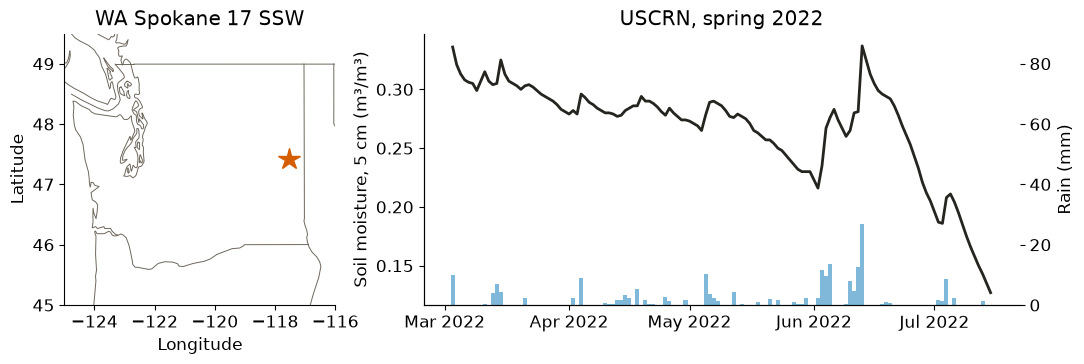

In [24]:
plot_station()

Two baselines come first. **Climatology** is the mean for that day of the year over the training years, smoothed over 15 days. **Yesterday's value** repeats the last measurement. A linear regression gives the third reference.

In [25]:
climatology = train.groupby("day_of_year")["moisture"].mean().reindex(range(1, 367)).interpolate().rolling(15, center=True, min_periods=1).mean()
references = {"climatology": test["day_of_year"].map(climatology).to_numpy(),
              "yesterday's value": test["moisture_yesterday"].to_numpy(),
              "linear regression": LinearRegression().fit(train[FEATURES], train["moisture"]).predict(test[FEATURES])}

### Your turn (5): does the forest beat them?

Fit `soil_forest`, a `RandomForestRegressor(n_estimators=N_TREES, random_state=SEED, n_jobs=-1)`, on `train[FEATURES]` and `train["moisture"]`. Then compute `p_soil`, its predictions for `test[FEATURES]`.

*Hint:* the same three lines as a classifier, with `.predict`.

In [26]:
soil_forest = None
p_soil = None

*Worked solution below (click ⋯ to open it).*

In [27]:
soil_forest_sol = RandomForestRegressor(n_estimators=N_TREES, random_state=SEED, n_jobs=-1).fit(train[FEATURES], train["moisture"])
check("soil_forest", globals(), soil_forest_sol, "RandomForestRegressor(...).fit(train[FEATURES], train['moisture'])",
      measure=lambda model: mean_absolute_error(test["moisture"], model.predict(test[FEATURES])), tol=0.001)
check("p_soil", globals(), soil_forest_sol.predict(test[FEATURES]), "soil_forest.predict(test[FEATURES])",
      measure=lambda p: mean_absolute_error(test["moisture"], p), tol=0.001)

soil_forest: not answered yet. Hint: RandomForestRegressor(...).fit(train[FEATURES], train['moisture'])
  Using the reference result below.
p_soil: not answered yet. Hint: soil_forest.predict(test[FEATURES])
  Using the reference result below.


In [28]:
rainy = test["rain_today"].to_numpy() >= RAIN_DAY_MM
rows = []
for name, p in {**references, "forest": p_soil}.items():
    rows.append({"model": name, "error (m3/m3)": mean_absolute_error(test["moisture"], p), "R2": r2_score(test["moisture"], p),
                 "error, rainy days": mean_absolute_error(test["moisture"][rainy], p[rainy])})
pd.DataFrame(rows).set_index("model").round(4)

,error (m3/m3),R2,"error, rainy days"
model,,,
climatology,0.0284,0.8483,0.0353
yesterday's value,0.0042,0.9952,0.0138
linear regression,0.0036,0.9972,0.0103
forest,0.0033,0.9971,0.0109


The error is the mean absolute error, in the units of the sensor. R² is the share of variance explained. Read the second row before the last: repeating yesterday's value already reaches a very high R², because soil moisture changes slowly. **A high R² on a slow variable says little until you compare it with persistence.**

## Part 6. A copy of a feature (skip if short of time)

Impurity importance measures how much each feature reduced the variance across all splits, on the training data. Yesterday's moisture dominates. Now add the same column again, in percent. It holds no new information about the soil.

### Your turn (6): where does the credit go?

Fit `copy_forest` with the same settings on `train_copy` (below), and store `copy_importance`, a `pd.Series` of its `feature_importances_` with `train_copy.columns` as the index.

*Hint:* `pd.Series(copy_forest.feature_importances_, index=train_copy.columns)`.

In [29]:
train_copy = train[FEATURES].assign(moisture_yesterday_percent=100 * train["moisture_yesterday"])
test_copy = test[FEATURES].assign(moisture_yesterday_percent=100 * test["moisture_yesterday"])

In [30]:
copy_forest = None
copy_importance = None

*Worked solution below (click ⋯ to open it).*

In [31]:
copy_forest_sol = RandomForestRegressor(n_estimators=N_TREES, random_state=SEED, n_jobs=-1).fit(train_copy, train["moisture"])
check("copy_forest", globals(), copy_forest_sol, "RandomForestRegressor(...).fit(train_copy, train['moisture'])",
      measure=lambda model: mean_absolute_error(test["moisture"], model.predict(test_copy)), tol=0.001)
check("copy_importance", globals(), pd.Series(copy_forest_sol.feature_importances_, index=train_copy.columns), "pd.Series(copy_forest.feature_importances_, index=train_copy.columns)", tol=0.05)

copy_forest: not answered yet. Hint: RandomForestRegressor(...).fit(train_copy, train['moisture'])
  Using the reference result below.
copy_importance: not answered yet. Hint: pd.Series(copy_forest.feature_importances_, index=train_copy.columns)
  Using the reference result below.


In [32]:
print(f"Error without the copy {mean_absolute_error(test['moisture'], p_soil):.4f}, with the copy {mean_absolute_error(test['moisture'], copy_forest.predict(test_copy)):.4f} m3/m3")
pd.DataFrame({"original features": pd.Series(soil_forest.feature_importances_, index=FEATURES), "with the copy": copy_importance}).sort_values("with the copy", ascending=False).round(3).fillna("")

Error without the copy 0.0033, with the copy 0.0034 m3/m3


,original features,with the copy
moisture_yesterday,0.991,0.527
moisture_yesterday_percent,,0.464
moisture_10cm_yesterday,0.003,0.003
rain_today,0.003,0.003
rain_yesterday,0.002,0.002
solar,0.001,0.001
air_temperature,0.0,0.000


The error did not change, and the credit split. Real features correlate the same way: moisture at 5 and 10 cm, temperature and solar radiation. Mayer et al. (2022) removed features correlated above r = 0.8 before reading their importance. Importance describes how this model used its inputs; it does not show cause.

## Part 7. Outside the training range

A forest's prediction is an average of training values. What happens on days hotter than any it has seen? Ground surface temperature follows air temperature closely (both from the same station), so this is a clean test. We train only on days with a maximum air temperature below 28 °C, keep a quarter of those days aside, and then predict the hot days. This is a designed test, as with the silica-rich rocks of notebook 3.2.

In [33]:
surface = pd.DataFrame({"air": station["T_DAILY_MAX"], "ground": station["SUR_TEMP_DAILY_MAX"]}).dropna()
cool, hot = surface[surface["air"] < COOL_LIMIT_C], surface[surface["air"] >= COOL_LIMIT_C]
held_out = cool.sample(frac=0.25, random_state=SEED)
fit_days = cool.drop(held_out.index)
print(f"{len(fit_days)} days to fit, {len(held_out)} cool days held out, {len(hot)} hot days")

2301 days to fit, 767 cool days held out, 570 hot days


### Your turn (7): a forest and a line

Fit `hot_forest` (same settings, on `fit_days[["air"]]` and `fit_days["ground"]`) and `hot_line`, a `LinearRegression` on the same data. Then fill `hot_errors`, a dictionary with the mean absolute error of each on the hot days: `{"forest": ..., "line": ...}`.

*Hint:* the double brackets keep `air` as a table with one column: `hot_forest.predict(hot[["air"]])`.

In [34]:
hot_forest = None
hot_line = None
hot_errors = None

*Worked solution below (click ⋯ to open it).*

In [35]:
hot_forest_sol = RandomForestRegressor(n_estimators=N_TREES, random_state=SEED, n_jobs=-1).fit(fit_days[["air"]], fit_days["ground"])
hot_line_sol = LinearRegression().fit(fit_days[["air"]], fit_days["ground"])
hot_mae = lambda model: mean_absolute_error(hot["ground"], model.predict(hot[["air"]]))
check("hot_forest", globals(), hot_forest_sol, "RandomForestRegressor(...).fit(fit_days[['air']], fit_days['ground'])", measure=hot_mae, tol=0.3)
check("hot_line", globals(), hot_line_sol, "LinearRegression().fit(fit_days[['air']], fit_days['ground'])", measure=hot_mae, tol=0.01)
check("hot_errors", globals(), {"forest": hot_mae(hot_forest_sol), "line": hot_mae(hot_line_sol)}, "mean_absolute_error(hot['ground'], model.predict(hot[['air']])) for each model",
      measure=lambda d: [d["forest"], d["line"]], tol=0.3)

hot_forest: not answered yet. Hint: RandomForestRegressor(...).fit(fit_days[['air']], fit_days['ground'])
  Using the reference result below.
hot_line: not answered yet. Hint: LinearRegression().fit(fit_days[['air']], fit_days['ground'])
  Using the reference result below.


hot_errors: not answered yet. Hint: mean_absolute_error(hot['ground'], model.predict(hot[['air']])) for each model
  Using the reference result below.


In [36]:
# Helper: both models over the whole range of air temperature, with the hot days they never saw.
def plot_extrapolation():
    fig, ax = plt.subplots(figsize=(7, 4.6))
    ax.scatter(fit_days["air"], fit_days["ground"], s=5, color="#b8b1a4", alpha=0.6, label="training days")
    ax.scatter(hot["air"], hot["ground"], s=8, color=ORANGE, alpha=0.6, label="hot days, not used in training")
    grid = pd.DataFrame({"air": np.linspace(surface["air"].min(), surface["air"].max(), 500)})
    ax.plot(grid["air"], hot_forest.predict(grid), color=GREEN, lw=2, label="forest")
    ax.plot(grid["air"], hot_line.predict(grid), color=BLUE, lw=2, label="linear regression")
    ax.axvline(COOL_LIMIT_C, color=INK, ls="--")
    ax.set(xlabel="Daily maximum air temperature (°C)", ylabel="Daily maximum ground temperature (°C)", title="USCRN WA Spokane 17 SSW, 2015 to 2024")
    ax.legend(frameon=False, loc="upper left")
    plt.show()

Cool days held out: forest 4.1, line 4.0 °C
Hot days:           forest 7.9, line 4.0 °C
Largest value on hot days: observed 67.6, forest 45.5, line 70.8 °C


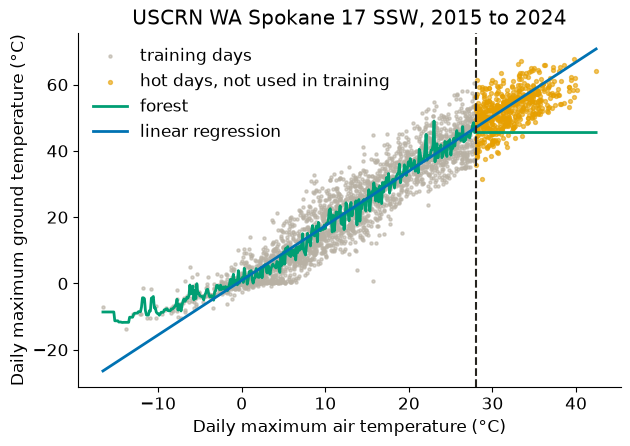

In [37]:
print(f"Cool days held out: forest {mean_absolute_error(held_out['ground'], hot_forest.predict(held_out[['air']])):.1f}, line {mean_absolute_error(held_out['ground'], hot_line.predict(held_out[['air']])):.1f} °C")
print(f"Hot days:           forest {hot_errors['forest']:.1f}, line {hot_errors['line']:.1f} °C")
print(f"Largest value on hot days: observed {hot['ground'].max():.1f}, forest {hot_forest.predict(hot[['air']]).max():.1f}, line {hot_line.predict(hot[['air']]).max():.1f} °C")
plot_extrapolation()

On the cool days the two models tie, so a validation set drawn from those days could not separate them. Above 28 °C the forest's curve goes flat. The line holds here only because this relation happens to be nearly straight: it would extrapolate just as confidently if the relation bent.

## Pause and discuss

1. In Part 4 the two models have nearly the same AUC. What would you need to know to choose one for an operational catalog?
2. In Part 5, the forest beats yesterday's value by about .0009 m³/m³. Is that gain worth having? What would you ask about the sensor?
3. **Your project:** in which conditions will your model be used outside the range of its training data? How would you test that before someone relies on it?

:::{dropdown} Points to bring out
1. Their costs: what a missed blast and a false alarm each cost, then a threshold chosen for each model on validation data. Also which features are available when the prediction is needed, how much preparation each model needs, and whether the probabilities are calibrated. The weights of logistic regression are simpler to read; a forest needs less preparation and held up better with few training events in the lecture's test.
2. Compare with the sensor's own uncertainty and its use. The gain is small on average, and on rainy days the linear model does about as well. A simple model may be the better choice here, and that is a useful result.
3. Answers will differ: another climate, volcano, sensor or network. The test is to hold out the conditions you expect, as Part 7 held out hot days, and as Monday's robust training will do with time, groups and regions.
:::

## Summary

| Question | Tool | Example | Result on these data |
|---|---|---|---|
| Where does a ROC curve come from? | one point per threshold | ten seismic events | AUC .76 by hand; .963 on 500 events |
| Why not one tree? | training against test score | four source types | macro-F1 1.000 against .800 |
| What do many trees add? | bootstrap, random features | four source types | .884 with 300 trees; logistic regression also .884 |
| Do thresholds transfer? | one threshold, two models | explosion or earthquake | 62 or 89 missed at 0.8 |
| Did the forest learn anything? | climatology, yesterday's value | Turnbull soil moisture | .0284, .0042, forest .0033 m³/m³ |
| What does importance show? | add a copy of a feature | Turnbull soil moisture | .99 splits into .53 and .46; same error |
| What happens outside training? | hold out hot days | ground surface temperature | forest error 4.1 to 7.9 °C; line 4.0 |

**Next.** Lessons [3.7](3.7_randomForest_regression.ipynb) and [3.9](3.9_ensemble_learning.ipynb) go further into partial dependence, boosting and stacking. Lesson [3.8](3.8_robust_training.ipynb) on Monday takes the train and test split itself as the question.

## References

- Bell, J. E., and others (2013). U.S. Climate Reference Network soil moisture and temperature observations. *Journal of Hydrometeorology*, 14, 977-988. [doi:10.1175/JHM-D-12-0146.1](https://doi.org/10.1175/JHM-D-12-0146.1)
- Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5-32. [doi:10.1023/A:1010933404324](https://doi.org/10.1023/A:1010933404324)
- Kharita, A., Denolle, M., Hutko, A., Hartog, R., and Malone, S. (2026). Exploration of machine learning methods to seismic event discrimination in the Pacific Northwest. *Seismica*, 5(1). [doi:10.26443/seismica.v5i1.2068](https://doi.org/10.26443/seismica.v5i1.2068)
- Mayer, S., van Herwijnen, A., Techel, F., and Schweizer, J. (2022). A random forest model to assess snow instability from simulated snow stratigraphy. *The Cryosphere*, 16, 4593-4615. [doi:10.5194/tc-16-4593-2022](https://doi.org/10.5194/tc-16-4593-2022)
- Poggio, L., and others (2021). SoilGrids 2.0: producing soil information for the globe with quantified spatial uncertainty. *SOIL*, 7, 217-240. [doi:10.5194/soil-7-217-2021](https://doi.org/10.5194/soil-7-217-2021)